# 05 · Train a classifier on the K-Means clusters
The clustering notebook gave every complaint a K-Means label. Here we teach a supervised model to predict that label from the complaint itself, so new complaints can be assigned to a cluster without re-running the clustering.

Steps: load → split → feature pipeline → compare 3 models → grid search + CV on the best → save one joblib file.

## 1. Setup

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, accuracy_score

RANDOM_STATE = 42

## 2. Load the data
The clean complaints and the cluster table share `complaint_id`.

In [2]:
clean = pd.read_csv("../data/clean/complaints_clean.csv")
clusters = pd.read_csv("../data/interim/complaints_clusters.csv", usecols=["complaint_id", "kmeans"])
df = clean.merge(clusters, on="complaint_id", how="inner")
print(clean.shape, clusters.shape, "->", df.shape)

(20551, 14) (20551, 2) -> (20551, 15)


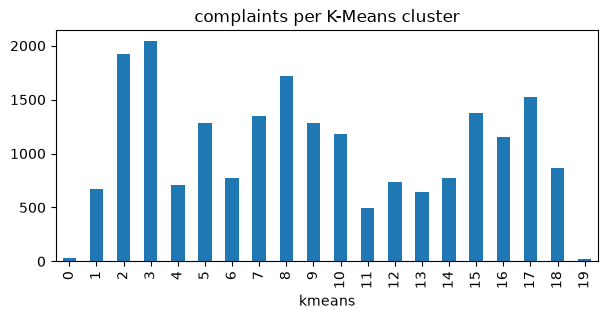

In [3]:
df["kmeans"].value_counts().sort_index().plot.bar(figsize=(7, 3), title="complaints per K-Means cluster");

16 clusters, none tiny (smallest is cluster 0 with about 850 complaints), so there is no serious class imbalance. We still stratify the split so every cluster keeps its share.

## 3. Choose the inputs
- `clean_text`: the main signal.
- `tags`, `submitted_via`: small categorical columns.
- `n_words`: complaint length.

Not used: `product`, `product_group`, `issue`, `sub_issue` (the clusters were meant to discover topics without them, and they would be unavailable or unreliable for a new complaint), and the ids and dates.

In [4]:
TEXT, CATS, NUMS = "clean_text", ["tags", "submitted_via"], ["n_words"]
X = df[[TEXT] + CATS + NUMS]
y = df["kmeans"]
X.head(3)

,clean_text,tags,submitted_via,n_words
0,i have an open and current mortgage with chase...,Older American,Web,67
1,my mortgage lender is refusing to cancel priva...,none,Web,182
2,i am a credit card account holder with chase m...,none,Web,193


## 4. Train / test split
80/20, stratified. The test set is touched once, at the very end.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(16440, 4) (4111, 4)


## 5. Feature engineering as a sklearn pipeline
One `ColumnTransformer` handles every column, so the same steps run on new data automatically:
- text → TF-IDF on words and word pairs
- categories → one-hot (unknown values ignored)
- length → `log1p` then scaled to 0-1

In [6]:
features = ColumnTransformer([
    ("text", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True), TEXT),
    ("cats", OneHotEncoder(handle_unknown="ignore"), CATS),
    ("nums", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", MinMaxScaler())]), NUMS),
])

In [ ]:
# process the data
X_train_processed = features.fit_transform(X_train)
X_text_processed = features.transform(X_test)

## 6. Compare three models
Same features, same 5-fold stratified CV on the **training** set only.
- Logistic regression: strong baseline for text.
- Linear SVM: usually the best on sparse TF-IDF.
- Complement Naive Bayes: very fast, made for text.

In [7]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "LinearSVC": LinearSVC(),
    "ComplementNB": ComplementNB(),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

In [8]:
rows = []
for name, clf in models.items():
    pipe = Pipeline([("features", features), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append((name, scores.mean(), scores.std()))
comparison = pd.DataFrame(rows, columns=["model", "f1_macro_mean", "f1_macro_std"]).sort_values("f1_macro_mean", ascending=False)
comparison.round(4)

,model,f1_macro_mean,f1_macro_std
1,LinearSVC,0.8233,0.0050
0,LogisticRegression,0.7825,0.0114
2,ComplementNB,0.7226,0.0038


In [9]:
best_name = comparison.iloc[0]["model"]
print("best model:", best_name)

best model: LinearSVC


## 7. Grid search + cross-validation on the best model
The grid searches the feature settings and the model settings together, because they live in the same pipeline.

In [10]:
grids = {
    "LogisticRegression": {"clf__C": [1, 3, 10]},
    "LinearSVC": {"clf__C": [0.1, 0.3, 1, 3]},
    "ComplementNB": {"clf__alpha": [0.03, 0.1, 0.3, 1]},
}
param_grid = {
    "features__text__ngram_range": [(1, 1), (1, 2)],
    "features__text__min_df": [3],
    **grids[best_name],
}
param_grid

{'features__text__ngram_range': [(1, 1), (1, 2)],
 'features__text__min_df': [3],
 'clf__C': [0.1, 0.3, 1, 3]}

In [11]:
pipe = Pipeline([("features", features), ("clf", models[best_name])])
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
print("best CV f1_macro:", round(search.best_score_, 4))
search.best_params_

Fitting 5 folds for each of 8 candidates, totalling 40 fits
best CV f1_macro: 0.8233


{'clf__C': 1,
 'features__text__min_df': 3,
 'features__text__ngram_range': (1, 2)}

In [12]:
cvres = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cvres[["rank_test_score", "mean_test_score", "std_test_score", "params"]].head(5)

,rank_test_score,mean_test_score,std_test_score,params
5,1,0.823256,0.004991,"{'clf__C': 1, 'features__text__min_df': 3, 'fe..."
7,2,0.821695,0.004760,"{'clf__C': 3, 'features__text__min_df': 3, 'fe..."
3,3,0.819276,0.004541,"{'clf__C': 0.3, 'features__text__min_df': 3, '..."
2,4,0.814646,0.007402,"{'clf__C': 0.3, 'features__text__min_df': 3, '..."
4,5,0.804512,0.005158,"{'clf__C': 1, 'features__text__min_df': 3, 'fe..."


## 8. Final check on the test set
The tuned pipeline was refit on the full training set. This is the first and only time we use the test set.

In [13]:
model = search.best_estimator_
pred = model.predict(X_test)
print("accuracy :", round(accuracy_score(y_test, pred), 4))
print("macro F1 :", round(f1_score(y_test, pred, average="macro"), 4))

accuracy : 0.819
macro F1 : 0.8205


In [14]:
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     0.714     0.833         7
           1      0.762     0.575     0.655       134
           2      0.789     0.859     0.823       384
           3      0.865     0.944     0.903       408
           4      0.930     0.936     0.933       141
           5      0.868     0.817     0.842       257
           6      0.918     0.942     0.930       155
           7      0.829     0.856     0.842       271
           8      0.733     0.802     0.766       343
           9      0.789     0.699     0.741       256
          10      0.804     0.814     0.809       237
          11      0.915     0.758     0.829        99
          12      0.893     0.899     0.896       148
          13      0.659     0.422     0.514       128
          14      0.861     0.883     0.872       154
          15      0.802     0.738     0.769       275
          16      0.833     0.818     0.825       231
          17      0.786    

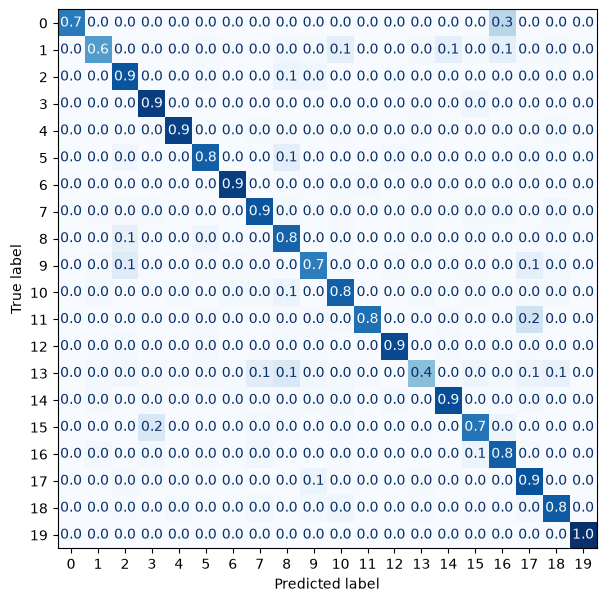

In [15]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, normalize="true", values_format=".1f", cmap="Blues", ax=ax, colorbar=False);

Read this as *how well can we reproduce K-Means from text*, not as accuracy against a ground truth. The labels came from an algorithm, so mistakes between neighbouring clusters (bright off-diagonal cells) mostly mean the clusters themselves overlap.

## 9. Look at what the model learned
Top words per cluster, from the model's weights (works for linear models).

In [16]:
vec = model.named_steps["features"].named_transformers_["text"]
clf = model.named_steps["clf"]
words = np.array(vec.get_feature_names_out())
if hasattr(clf, "coef_"):
    for k, cls in enumerate(clf.classes_):
        top = words[np.argsort(clf.coef_[k][:len(words)])[-8:][::-1]]
        print(f"cluster {cls:>2}: {', '.join(top)}")

cluster  0: only thought, thought is, statements my, how this, sure how, happened believe, statement did, you when
cluster  1: late fee, late fees, payment, late, fees, the payment, charged late, fee
cluster  2: atm, wire, money, transfer, wire transfer, debit, the wire, debit card
cluster  3: modification, escrow, insurance, loan, short sale, mortgage, home, property
cluster  4: inquiries, inquiry, hard, jpmcb, inquires, hard inquiry, jpmcb card, hard inquiries
cluster  5: check, checks, the check, deposited, cashed, deposit, check was, stop payment
cluster  6: points, annual, annual fee, the annual, offer, miles, rewards, fee
cluster  7: debt, calls, reporting, collection, report, credit report, the debt, this account
cluster  8: open, account, branch, closed, access, close, direct, direct deposit
cluster  9: charges, fraud, fraudulent, unauthorized, fraudulent charges, new card, card, unauthorized charges
cluster 10: limit, credit limit, cards, credit, closed, credit cards, score, a

## 10. Save everything as one file
`search.best_estimator_` is already a single pipeline: feature engineering + model. It takes a raw dataframe and returns cluster labels. One joblib file is all we need to deploy it.

In [17]:
Path('../models').mkdir(parents=True, exist_ok=True)
joblib.dump(model, "../models/kmeans_cluster_classifier.joblib")
import os; print(round(os.path.getsize("../models/kmeans_cluster_classifier.joblib") / 1e6, 1), "MB")

26.4 MB


## 11. Reload and test
A fresh load, fed with raw columns, should give the same predictions.

In [18]:
loaded = joblib.load("../models/kmeans_cluster_classifier.joblib")
sample = X_test.head(5)
print((loaded.predict(sample) == model.predict(sample)).all())
pd.DataFrame({"text": sample[TEXT].str[:80], "predicted": loaded.predict(sample), "kmeans": y_test.head(5).values})

True


,text,predicted,kmeans
20118,i purchased a refurbished exercise equipment f...,2,2
7681,on i submitted a complete request for mortgage...,3,3
13804,my ex husband and i needed to split our joint ...,14,14
3120,hello my name is i am well educated in finance...,3,3
11751,i was sent an email from on tuesday that state...,15,15


In [19]:
new = pd.DataFrame([{
    "clean_text": "someone hacked my account and moved money out without my permission",
    "tags": "none", "submitted_via": "Web", "n_words": 11}])
loaded.predict(new)

array([2])

Notes
- Logistic regression won in our run, so `predict_proba` is available. If a different model wins for you and it is the `LinearSVC` and you want a confidence score (for a human-review threshold, say), wrap it in `CalibratedClassifierCV` or use the logistic regression instead.
- To use the model on a new complaint you only need these four columns: `clean_text`, `tags`, `submitted_via`, `n_words`.